In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from scipy.ndimage import convolve

Διαστάσεις: (1168, 1752)
Min: 25.0
Max: 255.0


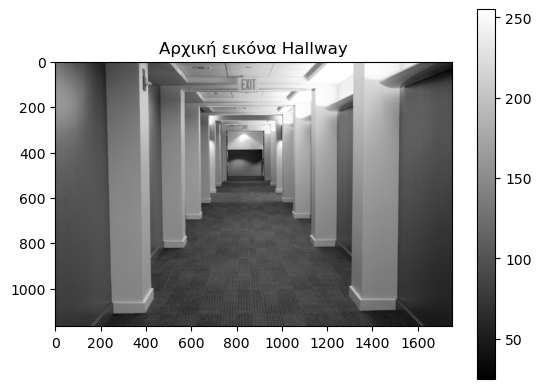

In [2]:
# Φόρτωση εικόνας
img = np.array(Image.open('hallway.png').convert('L'), dtype=float)

print(f"Διαστάσεις: {img.shape}")
print(f"Min: {img.min()}")
print(f"Max: {img.max()}")

plt.imshow(img, cmap='gray')
plt.title('Αρχική εικόνα Hallway')
plt.colorbar()
plt.show()

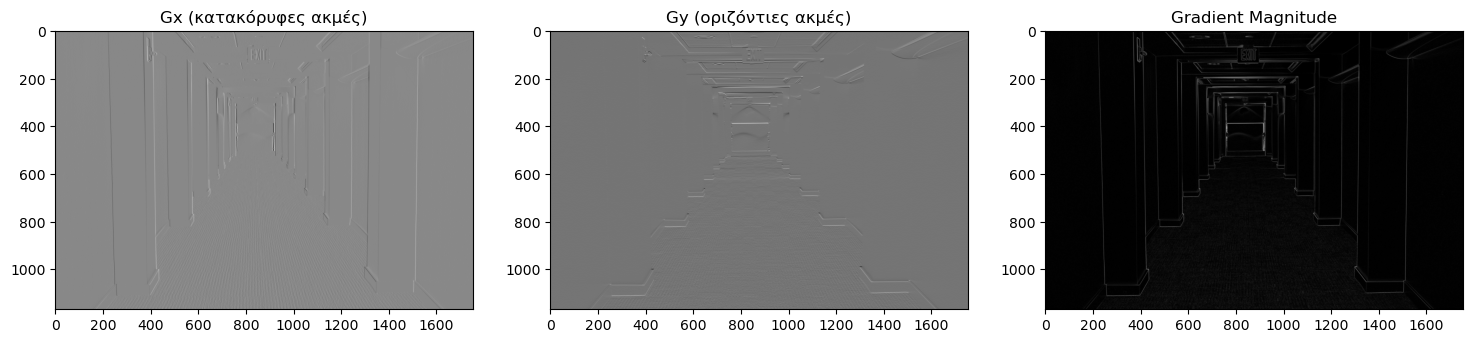

In [3]:
# Μάσκες Sobel
Sx = np.array([[-1, 0, 1],
               [-2, 0, 2],
               [-1, 0, 1]], dtype=float)

Sy = np.array([[-1, -2, -1],
               [ 0,  0,  0],
               [ 1,  2,  1]], dtype=float)

# Εφαρμογή συνέλιξης
Gx = convolve(img, Sx)
Gy = convolve(img, Sy)

# Gradient magnitude
G = np.sqrt(Gx**2 + Gy**2)

# Εμφάνιση
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(Gx, cmap='gray')
axes[0].set_title('Gx (κατακόρυφες ακμές)')
axes[1].imshow(Gy, cmap='gray')
axes[1].set_title('Gy (οριζόντιες ακμές)')
axes[2].imshow(G, cmap='gray')
axes[2].set_title('Gradient Magnitude')
plt.tight_layout()
plt.show()

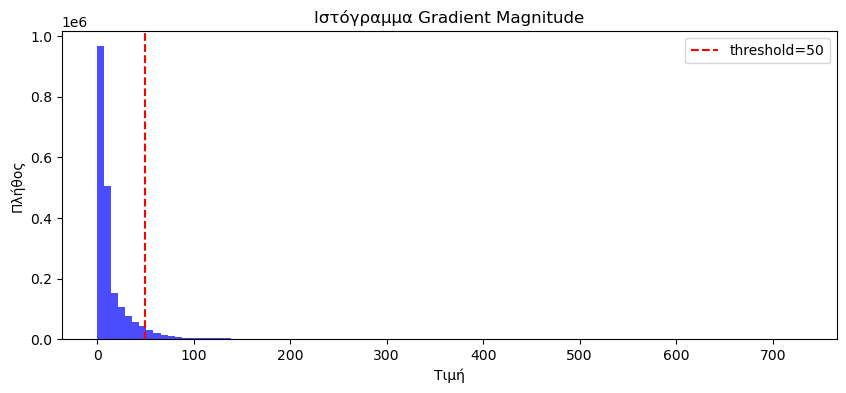

Min G: 0.00
Max G: 730.02
Mean G: 17.74


In [4]:
# Ιστόγραμμα gradient για επιλογή threshold
plt.figure(figsize=(10, 4))
plt.hist(G.ravel(), bins=100, color='blue', alpha=0.7)
plt.title('Ιστόγραμμα Gradient Magnitude')
plt.xlabel('Τιμή')
plt.ylabel('Πλήθος')
plt.axvline(x=50, color='red', linestyle='--', label='threshold=50')
plt.legend()
plt.show()

print(f"Min G: {G.min():.2f}")
print(f"Max G: {G.max():.2f}")
print(f"Mean G: {G.mean():.2f}")

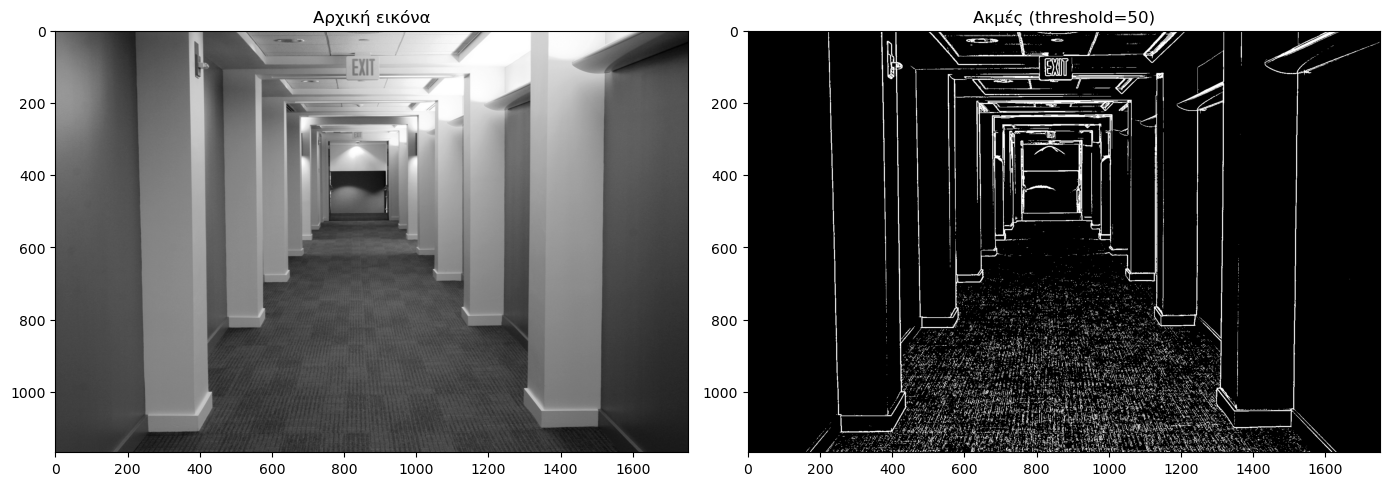

In [5]:
# Εφαρμογή threshold
threshold = 50
edges = (G > threshold).astype(float)

# Εμφάνιση
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Αρχική εικόνα')
axes[1].imshow(edges, cmap='gray')
axes[1].set_title(f'Ακμές (threshold={threshold})')
plt.tight_layout()
plt.show()

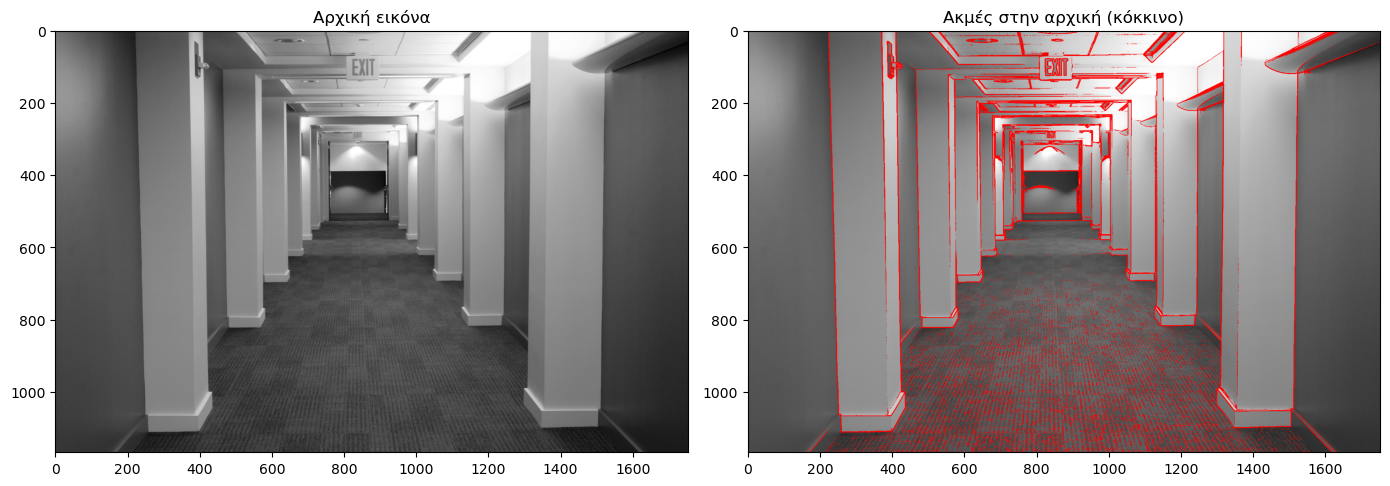

In [6]:
# Δημιουργία έγχρωμης εικόνας με ακμές
img_rgb = np.stack([img, img, img], axis=2).astype(np.uint8)

# Οι ακμές γίνονται κόκκινες
img_rgb[edges == 1, 0] = 255  # κόκκινο κανάλι
img_rgb[edges == 1, 1] = 0    # πράσινο κανάλι
img_rgb[edges == 1, 2] = 0    # μπλε κανάλι

# Εμφάνιση
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Αρχική εικόνα')
axes[1].imshow(img_rgb)
axes[1].set_title('Ακμές στην αρχική (κόκκινο)')
plt.tight_layout()
plt.show()